In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.graph_objects as go
import plotly.express as px

# Load results
revenue_df = pd.read_csv('../data/processed/revenue_at_risk.csv')
priority_list = pd.read_csv('../data/processed/priority_customers.csv')

print("=" * 70)
print("REVENUE AT-RISK ANALYSIS")
print("=" * 70)

print(f"\nRevenue At Risk Dataset:")
print(f"  Shape: {revenue_df.shape}")
print(f"  Columns: {revenue_df.columns.tolist()}")

print(f"\nSummary Statistics:")
print(f"  Total revenue at risk (3m): ${revenue_df['revenue_at_risk'].sum():,.0f}")
print(f"  Total revenue at risk (annual): ${revenue_df['annual_revenue_at_risk'].sum():,.0f}")
print(f"  High risk customers: {(revenue_df['risk_tier'] == 'High Risk').sum():,}")

print(f"\nFirst few rows:")
print(revenue_df.head())

REVENUE AT-RISK ANALYSIS

Revenue At Risk Dataset:
  Shape: (28800, 14)
  Columns: ['customer_id', 'churn_probability', 'risk_tier', 'health_score', 'monthly_revenue', 'subscription_tier', 'revenue_at_risk', 'annual_revenue_at_risk', 'churn_prob_norm', 'health_norm', 'revenue_norm', 'composite_risk_score', 'risk_rank', 'recommendation']

Summary Statistics:
  Total revenue at risk (3m): $9,937,608
  Total revenue at risk (annual): $39,750,432
  High risk customers: 2

First few rows:
  customer_id  churn_probability risk_tier  health_score  monthly_revenue  \
0   CUST_0001           0.041303  Low Risk     31.833333              500   
1   CUST_0001           0.097386  Low Risk     50.408333              500   
2   CUST_0001           0.149205  Low Risk     40.850000              500   
3   CUST_0001           0.170157  Low Risk     41.258333              500   
4   CUST_0001           0.125158  Low Risk     34.983333              500   

  subscription_tier  revenue_at_risk  annual_rev

REVENUE IMPACT VISUALIZATIONS


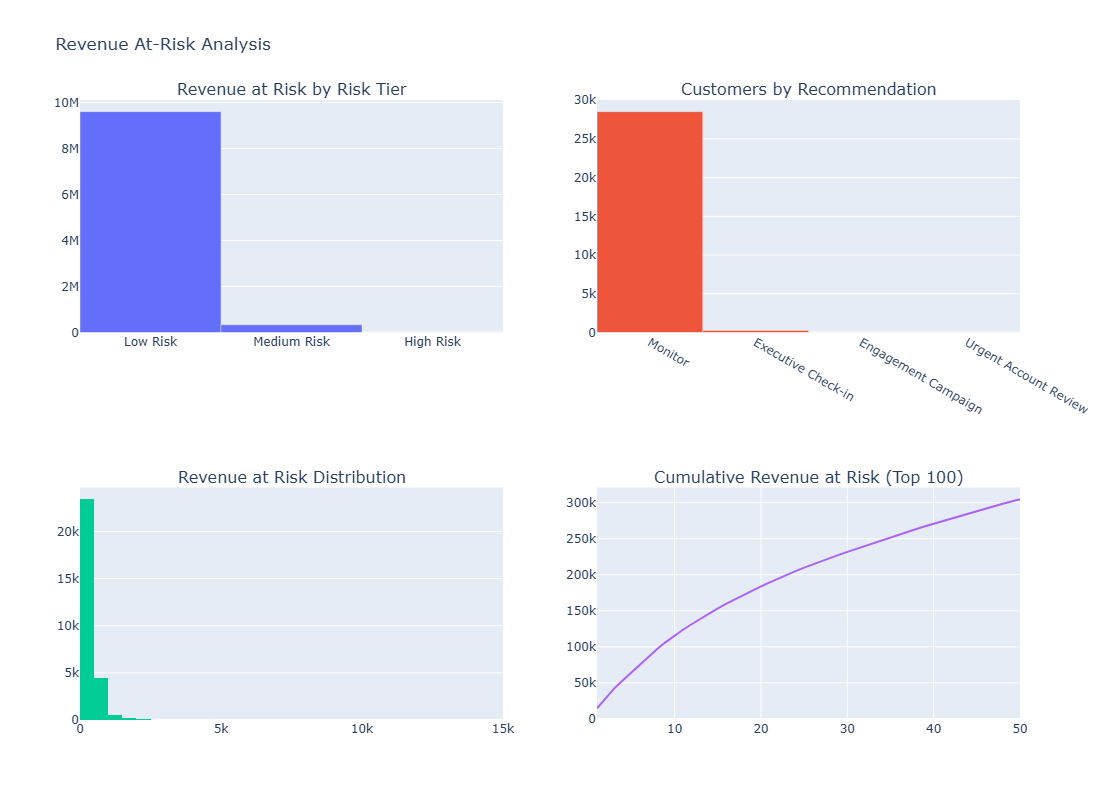

In [9]:
from plotly.subplots import make_subplots
import plotly.graph_objects as go

print("=" * 70)
print("REVENUE IMPACT VISUALIZATIONS")
print("=" * 70)

# Create visualizations
fig = make_subplots(
    rows=2, cols=2,
    subplot_titles=("Revenue at Risk by Risk Tier", 
                    "Customers by Recommendation",
                    "Revenue at Risk Distribution",
                    "Cumulative Revenue at Risk (Top 100)")
)

# Plot 1: Revenue by risk tier
revenue_by_risk = revenue_df.groupby('risk_tier')['revenue_at_risk'].sum().sort_values(ascending=False)
fig.add_trace(
    go.Bar(x=revenue_by_risk.index, y=revenue_by_risk.values, name='Revenue at Risk'),
    row=1, col=1
)

# Plot 2: Count by recommendation
rec_counts = revenue_df['recommendation'].value_counts()
fig.add_trace(
    go.Bar(x=rec_counts.index, y=rec_counts.values, name='Customer Count'),
    row=1, col=2
)

# Plot 3: Revenue distribution
fig.add_trace(
    go.Histogram(x=revenue_df['revenue_at_risk'], name='Distribution', nbinsx=30),
    row=2, col=1
)

# Plot 4: Cumulative (Pareto)
top_100 = priority_list.head(100).sort_values('revenue_at_risk', ascending=False)
cumsum = top_100['revenue_at_risk'].cumsum()
fig.add_trace(
    go.Scatter(x=list(range(1, len(top_100)+1)), y=cumsum, mode='lines', name='Cumulative'),
    row=2, col=2
)

fig.update_layout(height=800, showlegend=False, title_text="Revenue At-Risk Analysis")
fig.show()

In [11]:
print("=" * 70)
print("PRIORITY CUSTOMER ANALYSIS")
print("=" * 70)

print("\nTop 20 Customers by Revenue at Risk:")
top_20 = priority_list.head(20)[
    ['priority_rank', 'customer_id', 'monthly_revenue', 'churn_probability', 'recommendation']
]
print(top_20.to_string(index=False))

# Recommendations breakdown
print("\n" + "=" * 70)
print("RETENTION STRATEGY BY RECOMMENDATION")
print("=" * 70)

for rec in priority_list['recommendation'].unique():
    count = (priority_list['recommendation'] == rec).sum()
    total_revenue = priority_list[priority_list['recommendation'] == rec]['monthly_revenue'].sum()
    avg_churn = priority_list[priority_list['recommendation'] == rec]['churn_probability'].mean()
    
    print(f"\n{rec}:")
    print(f"  Customers: {count}")
    print(f"  Total MRR: ${total_revenue:,.0f}")
    print(f"  Avg Churn Prob: {avg_churn:.1%}")

PRIORITY CUSTOMER ANALYSIS

Top 20 Customers by Revenue at Risk:
 priority_rank customer_id  monthly_revenue  churn_probability     recommendation
             1   CUST_0795            10000           0.488774 Executive Check-in
             2   CUST_0266            10000           0.463491 Executive Check-in
             3   CUST_0634            10000           0.462673 Executive Check-in
             4   CUST_0592            10000           0.374171 Executive Check-in
             5   CUST_0634            10000           0.373068 Executive Check-in
             6   CUST_0705            10000           0.369098 Executive Check-in
             7   CUST_0024            10000           0.364544 Executive Check-in
             8   CUST_0520            10000           0.344530 Executive Check-in
             9   CUST_0795            10000           0.324753 Executive Check-in
            10   CUST_0608            10000           0.301672 Executive Check-in
            11   CUST_0174       

In [13]:
print("=" * 70)
print("BUSINESS CASE FOR RETENTION EFFORTS")
print("=" * 70)

# Calculate impact if we retain even 20% of high-risk customers
high_risk = revenue_df[revenue_df['risk_tier'] == 'High Risk']
revenue_at_risk = high_risk['annual_revenue_at_risk'].sum()

retention_scenarios = {
    '10% retention': 0.10,
    '20% retention': 0.20,
    '30% retention': 0.30,
    '50% retention': 0.50,
}

print(f"\nTotal Annual Revenue at Risk: ${revenue_at_risk:,.0f}")
print(f"From {len(high_risk):,} high-risk customers")

print(f"\nRetention Scenarios (Impact of Successful Interventions):")
print("-" * 70)

for scenario, pct in retention_scenarios.items():
    saved_revenue = revenue_at_risk * pct
    print(f"{scenario:20} → ${saved_revenue:>12,.0f} annual revenue saved")

print("\n" + "=" * 70)
print("RECOMMENDATION")
print("=" * 70)
print(f"""
Focus retention efforts on:
  1. {len(priority_list.head(10)):,} customers needing urgent review (${priority_list.head(10)['revenue_at_risk'].sum():,.0f} at risk)
  2. {(revenue_df['recommendation'] == 'Engagement Campaign').sum():,} customers in engagement campaigns
  3. {(revenue_df['recommendation'] == 'Onboarding Support').sum():,} customers needing training

Even 20% success rate = ${revenue_at_risk * 0.20:,.0f} saved annually
""")

BUSINESS CASE FOR RETENTION EFFORTS

Total Annual Revenue at Risk: $7,473
From 2 high-risk customers

Retention Scenarios (Impact of Successful Interventions):
----------------------------------------------------------------------
10% retention        → $         747 annual revenue saved
20% retention        → $       1,495 annual revenue saved
30% retention        → $       2,242 annual revenue saved
50% retention        → $       3,737 annual revenue saved

RECOMMENDATION

Focus retention efforts on:
  1. 10 customers needing urgent review ($116,003 at risk)
  2. 15 customers in engagement campaigns
  3. 0 customers needing training

Even 20% success rate = $1,495 saved annually



In [15]:
print("=" * 70)
print("PHASE 4 SUMMARY")
print("=" * 70)

total_mrr = revenue_df['monthly_revenue'].sum()
revenue_at_risk = revenue_df['revenue_at_risk'].sum()
high_risk_count = (revenue_df['risk_tier'] == 'High Risk').sum()
urgent_count = (revenue_df['recommendation'] == 'Urgent Account Review').sum()

summary = f"""
BUSINESS METRICS:
  Total Monthly Revenue: ${total_mrr:,.0f}
  High Risk Customers: {high_risk_count:,} ({high_risk_count/len(revenue_df)*100:.1f}%)
  3-Month Revenue at Risk: ${revenue_at_risk:,.0f}
  Annual Revenue at Risk: ${revenue_df['annual_revenue_at_risk'].sum():,.0f}

RETENTION PRIORITIES:
  Urgent Reviews Needed: {urgent_count:,} customers
  Total Priority List: {len(priority_list):,} customers
  Priority Revenue at Risk: ${priority_list['revenue_at_risk'].sum():,.0f}

KEY RECOMMENDATIONS:
  1. Focus on top 50 customers (${priority_list.head(50)['revenue_at_risk'].sum():,.0f} at risk)
  2. Implement urgent account reviews for {urgent_count:,} customers
  3. Run engagement campaigns for {(revenue_df['recommendation'] == 'Engagement Campaign').sum():,} customers

EXPECTED IMPACT (20% retention):
  Revenue Saved Annually: ${revenue_df['annual_revenue_at_risk'].sum() * 0.20:,.0f}

DELIVERABLES:
  - Revenue at risk: data/processed/revenue_at_risk.csv
  - Priority list: data/processed/priority_customers.csv
  - Risk scoring: composite_risk_score column
  - Recommendations: recommendation column for each customer

READY FOR PHASE 6 (DASHBOARD):
  - All data ready for visualization
  - Priority customers identified
  - Revenue impact calculated
"""

print(summary)

# Save summary
with open('../data/processed/phase_4_summary.txt', 'w', encoding='utf-8') as f:
    f.write(summary)

print("\nSummary saved to: data/processed/phase_4_summary.txt")

PHASE 4 SUMMARY

BUSINESS METRICS:
  Total Monthly Revenue: $73,674,000
  High Risk Customers: 2 (0.0%)
  3-Month Revenue at Risk: $9,937,608
  Annual Revenue at Risk: $39,750,432

RETENTION PRIORITIES:
  Urgent Reviews Needed: 1 customers
  Total Priority List: 50 customers
  Priority Revenue at Risk: $304,818

KEY RECOMMENDATIONS:
  1. Focus on top 50 customers ($304,818 at risk)
  2. Implement urgent account reviews for 1 customers
  3. Run engagement campaigns for 15 customers

EXPECTED IMPACT (20% retention):
  Revenue Saved Annually: $7,950,086

DELIVERABLES:
  - Revenue at risk: data/processed/revenue_at_risk.csv
  - Priority list: data/processed/priority_customers.csv
  - Risk scoring: composite_risk_score column
  - Recommendations: recommendation column for each customer

READY FOR PHASE 6 (DASHBOARD):
  - All data ready for visualization
  - Priority customers identified
  - Revenue impact calculated


Summary saved to: data/processed/phase_4_summary.txt
